# Laptop Price Prediction

Predict laptop prices from hardware specifications using **regression models** in Python. This project covers data exploration, feature engineering, model comparison, hyperparameter tuning, and model evaluation.

![Laptop price distribution by RAM](laptop_price_animation.gif)

*Observed laptop prices by RAM (animation displays real records, not predictions). Price units follow the supplied dataset; no currency is specified in the file*

**Project objective**

Build and compare regression models to estimate laptop prices based on brand, type, RAM, storage, CPU/GPU, screen, and other specifications. We evaluate models using **MAE**, **RMSE**, and **R²**.

**Import libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from xgboost import XGBRegressor

**Load data**

In [2]:
df = pd.read_csv("laptop_data.csv").drop(columns="Unnamed: 0")
df = df.drop_duplicates().reset_index(drop=True)
print("Rows, columns:", df.shape)
display(df.head())

Rows, columns: (1274, 11)


,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


**Exploratory data analysis**

In [3]:
print("Missing values:", df.isna().sum().sum())
print("Median price:", round(df["Price"].median(), 2))
display(df[["Inches", "Price"]].describe().round(2))

Missing values: 0
Median price: 52693.92


,Inches,Price
count,1274.00,1274.00
mean,15.02,60503.19
std,1.43,37333.22
min,10.10,9270.72
25%,14.00,32495.61
50%,15.60,52693.92
75%,15.60,79773.48
max,18.40,324954.72


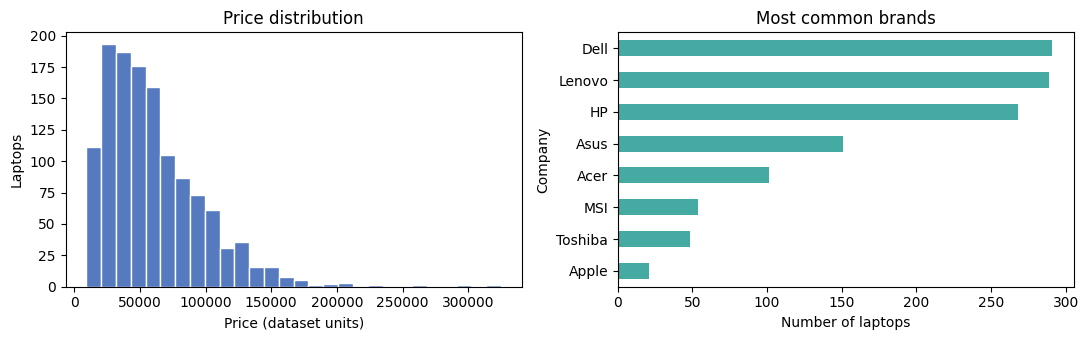

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(df["Price"], bins=28, color="#557abf", edgecolor="white")
axes[0].set(title="Price distribution", xlabel="Price (dataset units)", ylabel="Laptops")
df["Company"].value_counts().head(8).sort_values().plot.barh(ax=axes[1], color="#44aaa2")
axes[1].set(title="Most common brands", xlabel="Number of laptops")
plt.tight_layout()
plt.show()

**Feature engineering**

Convert RAM and weight to numeric values; extract TouchScreen, IPS, storage indicators, and simplified CPU/GPU brands. These are the features our regression models will use

In [5]:
df["RamGB"] = df["Ram"].str.replace("GB", "", regex=False).astype(int)
df["WeightKG"] = df["Weight"].str.replace("kg", "", regex=False).astype(float)
df["TouchScreen"] = df["ScreenResolution"].str.contains("Touchscreen", case=False).astype(int)
df["IPS"] = df["ScreenResolution"].str.contains("IPS", case=False).astype(int)
df["SSD"] = df["Memory"].str.contains("SSD").astype(int)
df["HDD"] = df["Memory"].str.contains("HDD").astype(int)
df["CpuFamily"] = df["Cpu"].str.split().str[:3].str.join(" ")
df["GpuBrand"] = df["Gpu"].str.split().str[0]
df["Resolution"] = df["ScreenResolution"].str.extract(r"(\d+x\d+)")[0]
for kind in ["SSD", "HDD"]:
    size = df["Memory"].str.extract(r"(\d+(?:\.\d+)?)\s*(TB|GB)\s*" + kind)
    df[kind + "GB"] = pd.to_numeric(size[0], errors="coerce").fillna(0)
    df[kind + "GB"] *= np.where(size[1].eq("TB"), 1024, 1)

**Prepare training and test data**

In [6]:
features = ["Company", "TypeName", "Inches", "RamGB", "WeightKG",
            "TouchScreen", "IPS", "SSD", "HDD", "SSDGB", "HDDGB", "CpuFamily", "GpuBrand", "OpSys", "Resolution"]
X = pd.get_dummies(df[features], dtype=int)
y = df["Price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1019, 102) | Test: (255, 102)


**Train and compare regression models**

All five models are trained on the same training split and evaluated on the held-out test data

In [7]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=9, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1),
    "AdaBoost": AdaBoostRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=180, max_depth=4, learning_rate=0.08,
                            objective="reg:squarederror", random_state=42, n_jobs=2)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    results.append({"Model": name,
                    "MAE": mean_absolute_error(y_test, predictions),
                    "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
                    "R2": r2_score(y_test, predictions)})

scores = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
display(scores.round(3))

,Model,MAE,RMSE,R2
0,Random Forest,10871.539,18248.127,0.806
1,XGBoost,11243.640,18052.121,0.810
2,Linear Regression,12835.512,20014.792,0.766
3,Decision Tree,13721.644,23682.695,0.673
4,AdaBoost,18412.584,23546.967,0.676


**Model performance visualization**

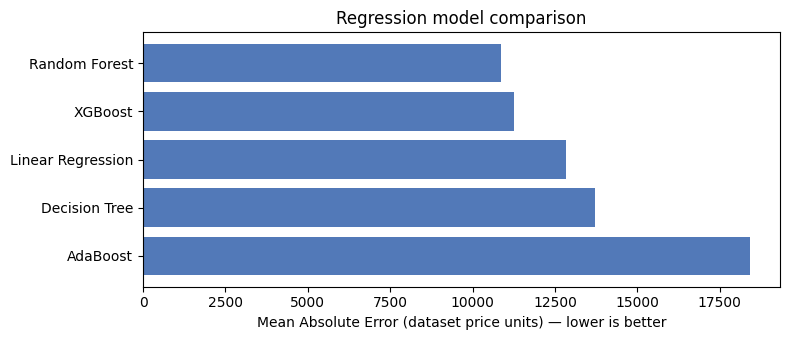

In [8]:
plt.figure(figsize=(8, 3.5))
plt.barh(scores["Model"], scores["MAE"], color="#5279b8")
plt.gca().invert_yaxis()
plt.xlabel("Mean Absolute Error (dataset price units) — lower is better")
plt.title("Regression model comparison")
plt.tight_layout()
plt.show()

**Hyperparameter tuning**

Use `GridSearchCV` to tune Random Forest **only on the training data**. Compare its test-set MAE with the untuned version

In [9]:
params = {"n_estimators": [100, 150], "max_depth": [None, 12], "min_samples_leaf": [1, 2]}
search = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=2),
                      params, cv=3, scoring="neg_mean_absolute_error", n_jobs=2)
search.fit(X_train, y_train)
model = search.best_estimator_
final_pred = model.predict(X_test)
print("Best parameters:", search.best_params_)
print("Tuned Random Forest — MAE:", round(mean_absolute_error(y_test, final_pred), 2))
print("Tuned Random Forest — RMSE:", round(np.sqrt(mean_squared_error(y_test, final_pred)), 2))
print("Tuned Random Forest — R²:", round(r2_score(y_test, final_pred), 3))

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 150}
Tuned Random Forest — MAE: 10871.54
Tuned Random Forest — RMSE: 18248.13
Tuned Random Forest — R²: 0.806


**Actual vs. predicted prices**

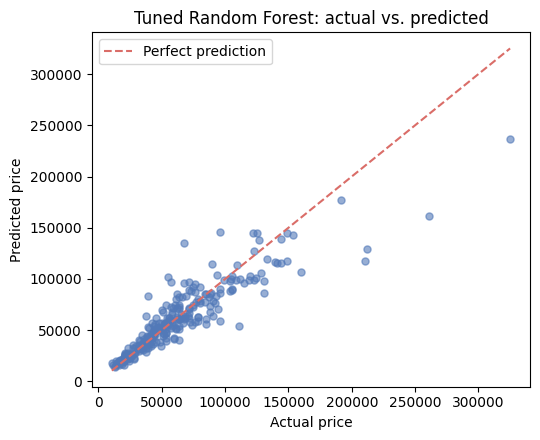

In [10]:
plt.figure(figsize=(5.5, 4.5))
plt.scatter(y_test, final_pred, alpha=0.6, s=26, color="#5279b8")
limits = [min(y_test.min(), final_pred.min()), max(y_test.max(), final_pred.max())]
plt.plot(limits, limits, "--", color="#da6d68", label="Perfect prediction")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Tuned Random Forest: actual vs. predicted")
plt.legend()
plt.tight_layout()
plt.show()

**Feature importance**

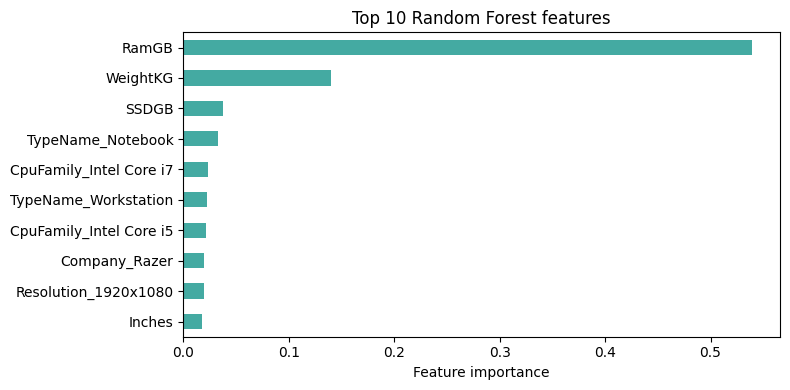

In [11]:
importances = pd.Series(model.feature_importances_, index=X_train.columns)
importances.nlargest(10).sort_values().plot.barh(figsize=(8, 4), color="#44aaa2")
plt.xlabel("Feature importance")
plt.title("Top 10 Random Forest features")
plt.tight_layout()
plt.show()

**Example predictions**

In [12]:
comparison = pd.DataFrame({"Actual": y_test.values, "Predicted": final_pred}).round(2)
comparison["Absolute Error"] = (comparison["Actual"] - comparison["Predicted"]).abs().round(2)
display(comparison.head(8))

,Actual,Predicted,Absolute Error
0,24988.32,25696.51,708.19
1,41345.28,35071.88,6273.40
2,63882.72,40293.82,23588.90
3,42357.60,45606.62,3249.02
4,68184.01,61805.46,6378.55
5,38308.32,37688.44,619.88
6,111355.20,54335.84,57019.36
7,31808.16,35211.98,3403.82


**Conclusion**

Five regression models were compared using **MAE**, **RMSE**, and **R²**. On this test split, **Random Forest** achieved the lowest MAE (10,871.54), while **XGBoost** achieved the highest R² (0.810) and the lowest RMSE (18,052.12).

**Hyperparameter tuning:** GridSearchCV selected the same Random Forest parameters as the original model, so tuning did not improve the hold-out metrics in this run.

**Limitations:** Prices come from the historical dataset, not current market offers. The currency is unspecified. A random split may not represent unseen brands or future laptops. The GIF shows observed prices, not model predictions.